# Exercise 1 

In this exercise, we will work with the `spam.csv` data file. This file contains text and a label attached to each text. The goal is to clean the text data and then build classifcation models. 

### Exercise 1(a) (2 points)

Load the `pandas` and `numpy` libraries.

In [1]:
import pandas as pd 
import numpy as np

### Exercise 1(b) (2 points)

Read the `csv` file and create a data-frame called `spam_df`.

In [2]:
spam_df = pd.read_csv("spam.csv")
spam_df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Exercise 1(c) (2 points)

Using the `string` library, remove all the punctuation of the `text` column.

In [3]:
import string 

spam_df["text_clean"] = spam_df["text"].str.replace(f"[{string.punctuation}]", "", regex=True)
spam_df.head()

,label,text,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...


### Exercise 1(d) (10 points)

Using the `nltk` library, remove stopwords and pronouns from `text_clean` and store in another column called `'text_clean_1'`. 

In [4]:
import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
pronouns = ['i', 'he', 'she', 'it', 'they', 'we', 'him', 'her', 'his', 'their', 'our', 'u', 'ur', 'im', 'dont', '2', 'ill', '4']

def clean_text(text):

    # Tokenize the text
    tokens = word_tokenize(text.lower())

    # Remove unwanted words
    tokens = [word for word in tokens if word not in stop_words and word not in pronouns]

    # Replacing words
    tokens = [word.replace('txt', 'text') for word in tokens]

    return ' '.join(tokens)

spam_df['text_clean_1'] = spam_df['text_clean'].apply(clean_text)
spam_df.head()

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/oscarm524/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/oscarm524/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/oscarm524/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,label,text,text_clean,text_clean_1
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though


### Exercise 1(e) (10 points)

Perform Lemmatization of `text_clean_1` and store the results in another column called `text_clean_2` in the `spam_df` data frame.

In [5]:
from nltk.corpus import wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Download necessary NLTK resources
nltk.download('wordnet')
nltk.download("averaged_perceptron_tagger")
nltk.download('averaged_perceptron_tagger_eng')

# Initialize the lemmatizer
lemmatizer = WordNetLemmatizer()

# Function to get the part of speech tag for lemmatization
def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

# Function to lemmatize text
def lemmatize_text(text):
    words = word_tokenize(text)
    lemmatized_words = [lemmatizer.lemmatize(word, get_wordnet_pos(word)) for word in words]
    return ' '.join(lemmatized_words)

# Apply the function to lemmatize the text
spam_df['text_clean_2'] = spam_df['text_clean_1'].apply(lemmatize_text)
spam_df.head()

[nltk_data] Downloading package wordnet to
[nltk_data]     /home/oscarm524/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/oscarm524/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/oscarm524/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


,label,text,text_clean,text_clean_1,text_clean_2
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though,nah think go usf life around though


### Exercise 1(f) (5 points)

Based on the results from part 1(f), we see digits in some of the text in `text_clean_2`. Remove all the digits from `text_clean_2` and store the results in another column `text_clean_3` in the `spam_df` data frame.

In [6]:
import re

# Function to remove numbers
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

# Apply the function to remove numbers from the cleaned text
spam_df['text_clean_3'] = spam_df['text_clean_2'].apply(remove_numbers)
spam_df.head()

,label,text,text_clean,text_clean_1,text_clean_2,text_clean_3
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni,ok lar joking wif oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say,dun say early hor c already say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though,nah think go usf life around though,nah think go usf life around though


### Exercise 1(g) (5 points)

Generate embedding using the `BERT` model on `text_clean_3`.

In [7]:
from sentence_transformers import SentenceTransformer

print("Loading BERT model...")
bert_model = SentenceTransformer('all-MiniLM-L6-v2')
print("BERT model loaded.")

# Generate the embeddings
print("Generating embeddings...")
bert_embeddings = bert_model.encode(spam_df['text_clean_3'].tolist(),
                                    show_progress_bar=True,
                                    batch_size=32)

print("Embeddings generated.")
print(f"BERT embeddings shape: {bert_embeddings.shape}")
print(f"Each embedding vector length: {len(bert_embeddings[0])}")

/home/oscarm524/.local/lib/python3.10/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange
2026-10-29 19:33:33.651258: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-29 19:33:33.881596: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F AVX512_VNNI AVX512_BF16, in other operations, rebuild TensorFlow with the appropriate compiler flags.


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Loading BERT model...
BERT model loaded.
Generating embeddings...


Batches:   0%|          | 0/175 [00:00<?, ?it/s]

Embeddings generated.
BERT embeddings shape: (5572, 384)
Each embedding vector length: 384


### Exercise 1(h) (5 points)

Compute and visualize the principal components of the bert embedding.

PCA embeddings shape: (5572, 2)


/home/oscarm524/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


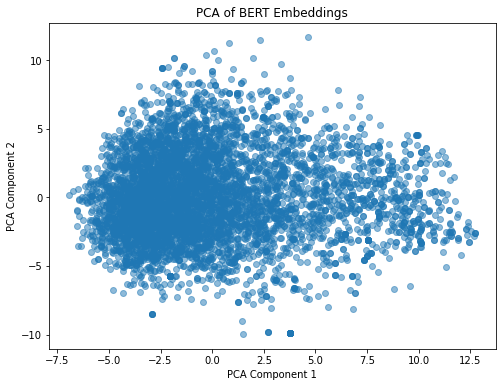

In [8]:
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Initilize the PCA model
pca = PCA(n_components=2)

# Standardize the embeddings before applying PCA
scaler = StandardScaler()
bert_embeddings_scaled = scaler.fit_transform(bert_embeddings)

# Apply PCA to the scaled embeddings
bert_embeddings_pca = pca.fit_transform(bert_embeddings_scaled)
print(f"PCA embeddings shape: {bert_embeddings_pca.shape}")

# Plot the PCA embeddings
plt.figure(figsize=(8, 6))
plt.scatter(bert_embeddings_pca[:, 0], bert_embeddings_pca[:, 1], alpha=0.5)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA of BERT Embeddings')
plt.show();

### Exercise 1(i) (5 points)

Project and visualize the bert embedding with `TSNE`.

t-SNE embeddings shape: (5572, 2)


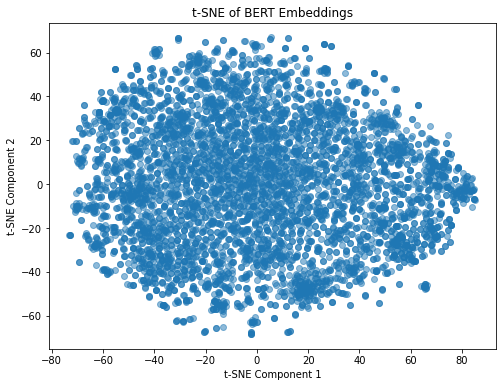

In [9]:
from sklearn.manifold import TSNE

# Initialize the t-SNE model
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)

# Apply t-SNE to the scaled embeddings
bert_embeddings_tsne = tsne.fit_transform(bert_embeddings_scaled)
print(f"t-SNE embeddings shape: {bert_embeddings_tsne.shape}")

# Plot the t-SNE embeddings
plt.figure(figsize=(8, 6))
plt.scatter(bert_embeddings_tsne[:, 0], bert_embeddings_tsne[:, 1], alpha=0.5)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE of BERT Embeddings')
plt.show();

### Exercise 1(j) (5 points)

Estimate the number of clusters on the bert embedding using silhouette, Calinski Harabasz, and Davies Bouldin scores. 

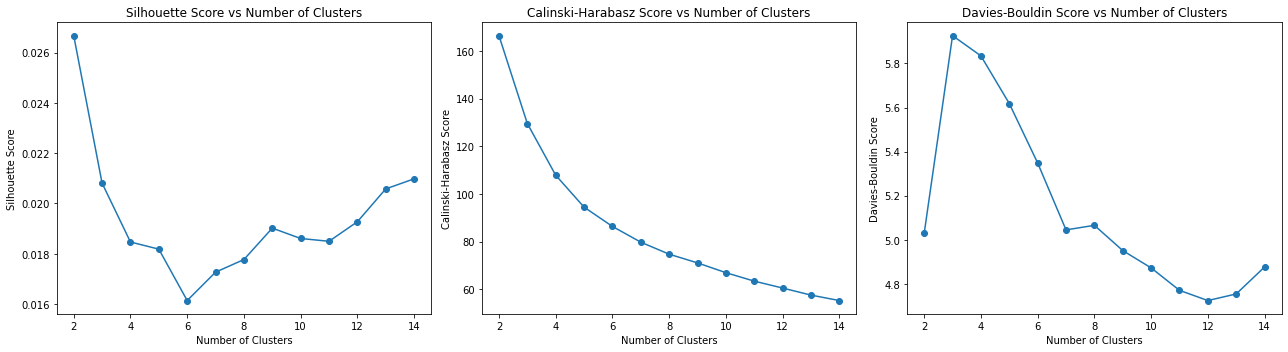

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

sil_scores, calinski_scores, davies_scores = [], [], []
for n_clusters in range(2, 15):

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=20)
    cluster_labels = kmeans.fit_predict(bert_embeddings_scaled)

    sil_scores.append(silhouette_score(bert_embeddings_scaled, cluster_labels))
    calinski_scores.append(calinski_harabasz_score(bert_embeddings_scaled, cluster_labels))
    davies_scores.append(davies_bouldin_score(bert_embeddings_scaled, cluster_labels))


plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
plt.plot(range(2, 15), sil_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')

plt.subplot(1, 3, 2)
plt.plot(range(2, 15), calinski_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Calinski-Harabasz Score')
plt.title('Calinski-Harabasz Score vs Number of Clusters')

plt.subplot(1, 3, 3)
plt.plot(range(2, 15), davies_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Davies-Bouldin Score')
plt.title('Davies-Bouldin Score vs Number of Clusters')

plt.tight_layout()
plt.show();